# Multipool Spot Price Data Analysis
Kiểm tra chất lượng data trước khi train — 4 scenarios × 5 types × 3 AZs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

import sys, os
sys.path.insert(0, os.path.abspath('..'))

DATA_DIR = '../data/processed'
SCENARIOS = ['stable', 'volatile', 'spike', 'az_divergence']
INSTANCE_TYPES = ['m5.large', 'c5.xlarge', 'r5.large', 'm5.xlarge', 'c5.2xlarge']
AZS = ['ap-southeast-1a', 'ap-southeast-1b', 'ap-southeast-1c']

# AWS on-demand prices ($/hr) — baseline reference
OD_PRICES = {
    'm5.large':   0.096,
    'c5.xlarge':  0.170,
    'r5.large':   0.126,
    'm5.xlarge':  0.192,
    'c5.2xlarge': 0.340,
}

dfs = {}
for scn in SCENARIOS:
    path = f'{DATA_DIR}/multipool_{scn}.csv'
    dfs[scn] = pd.read_csv(path)
    dfs[scn]['timestamp'] = pd.to_datetime(dfs[scn]['timestamp'])
    print(f'{scn:15s}: {len(dfs[scn]):7,} rows | types={dfs[scn]["instance_type"].nunique()} | AZs={dfs[scn]["availability_zone"].nunique()}')

print('\nColumns:', dfs['stable'].columns.tolist())

stable         : 129,600 rows | types=5 | AZs=3
volatile       : 129,600 rows | types=5 | AZs=3
spike          : 129,600 rows | types=5 | AZs=3
az_divergence  : 129,600 rows | types=5 | AZs=3

Columns: ['timestamp', 'spot_price', 'instance_type', 'availability_zone', 'price_ma_1h', 'price_ma_24h', 'price_volatility_24h', 'price_cv_24h', 'price_trend', 'hour_of_day', 'day_of_week', 'capacity_depth', 'est_interruption_prob', 'sps_score', 'rebalance_flag', 'termination_flag']


## 1. Sanity check — schema & completeness

In [2]:
print('=== SCHEMA CHECK ===')
for scn in SCENARIOS:
    df = dfs[scn]
    missing = df.isnull().sum()
    has_all_types = set(INSTANCE_TYPES).issubset(set(df['instance_type'].unique()))
    has_all_azs   = set(AZS).issubset(set(df['availability_zone'].unique()))
    rows_per_pool = len(df) / (len(INSTANCE_TYPES) * len(AZS))
    print(f'\n{scn}:')
    print(f'  Rows: {len(df):,}  ({rows_per_pool:.0f} per pool)')
    print(f'  All instance types: {has_all_types}  All AZs: {has_all_azs}')
    print(f'  Nulls: {missing[missing>0].to_dict() or "none"}')
    print(f'  Price range: ${df["spot_price"].min():.4f} - ${df["spot_price"].max():.4f}')
    print(f'  Negative prices: {(df["spot_price"] <= 0).sum()}')
    print(f'  capacity_depth range: [{df["capacity_depth"].min():.2f}, {df["capacity_depth"].max():.2f}]')

=== SCHEMA CHECK ===

stable:
  Rows: 129,600  (8640 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0520 - $0.1796
  Negative prices: 0
  capacity_depth range: [0.10, 1.00]

volatile:
  Rows: 129,600  (8640 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0493 - $0.2364
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]

spike:
  Rows: 129,600  (8640 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0492 - $0.3096
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]

az_divergence:
  Rows: 129,600  (8640 per pool)
  All instance types: True  All AZs: True
  Nulls: none
  Price range: $0.0512 - $0.2299
  Negative prices: 0
  capacity_depth range: [0.00, 1.00]


## 2. Spot price vs On-Demand ratio — phải trong khoảng 20-80%

In [3]:
print('=== SPOT/OD RATIO (realistic: 20%-80%) ===')
for scn in SCENARIOS:
    df = dfs[scn].copy()
    df['od_price'] = df['instance_type'].map(OD_PRICES)
    df['ratio'] = df['spot_price'] / df['od_price']
    print(f'\n{scn}:')
    for itype in INSTANCE_TYPES:
        sub = df[df['instance_type'] == itype]
        r = sub['ratio']
        flag = '' if 0.15 <= r.mean() <= 0.85 else '  *** OUT OF RANGE ***'
        print(f'  {itype:12s}: mean={r.mean():.1%}  [{r.min():.1%}-{r.max():.1%}]  std={r.std():.1%}{flag}')

=== SPOT/OD RATIO (realistic: 20%-80%) ===

stable:
  m5.large    : mean=56.1%  [54.2%-60.3%]  std=0.8%
  c5.xlarge   : mean=54.8%  [53.0%-57.5%]  std=0.8%
  r5.large    : mean=54.9%  [52.9%-58.9%]  std=0.7%
  m5.xlarge   : mean=55.1%  [52.9%-56.9%]  std=0.9%
  c5.2xlarge  : mean=51.1%  [49.1%-52.8%]  std=0.8%

volatile:
  m5.large    : mean=55.8%  [51.3%-81.0%]  std=1.7%
  c5.xlarge   : mean=54.5%  [50.2%-79.1%]  std=1.6%
  r5.large    : mean=53.9%  [50.0%-70.4%]  std=1.4%
  m5.xlarge   : mean=54.2%  [50.2%-78.0%]  std=1.5%
  c5.2xlarge  : mean=50.9%  [46.4%-69.5%]  std=1.6%

spike:
  m5.large    : mean=55.7%  [51.3%-99.0%]  std=2.3%
  c5.xlarge   : mean=55.4%  [49.8%-99.1%]  std=2.3%
  r5.large    : mean=54.1%  [49.7%-95.8%]  std=1.9%
  m5.xlarge   : mean=55.3%  [50.6%-98.2%]  std=2.1%
  c5.2xlarge  : mean=51.0%  [47.0%-91.0%]  std=2.1%

az_divergence:
  m5.large    : mean=55.7%  [53.4%-67.8%]  std=0.8%
  c5.xlarge   : mean=55.0%  [52.6%-75.6%]  std=0.9%
  r5.large    : mean=54.8%  [

## 3. Spike frequency — phải < 2%/h (AWS realistic)

In [4]:
print('=== SPIKE FREQUENCY (realistic: <2%/h) ===')
SPIKE_THRESH = 0.15  # >15% jump trong 1 step = spike

for scn in SCENARIOS:
    df = dfs[scn].copy()
    print(f'\n{scn}:')
    for itype in INSTANCE_TYPES:
        for az in AZS:
            sub = df[(df['instance_type']==itype) & (df['availability_zone']==az)].sort_values('timestamp')
            pct_change = sub['spot_price'].pct_change().abs()
            n_spikes = (pct_change > SPIKE_THRESH).sum()
            spike_rate = n_spikes / len(sub) * 100
            flag = '  ***' if spike_rate > 2.0 else ''
            if n_spikes > 0:
                print(f'  {itype} {az[-2:]}: {n_spikes} spikes ({spike_rate:.2f}%){flag}')

=== SPIKE FREQUENCY (realistic: <2%/h) ===

stable:

volatile:
  m5.large 1a: 18 spikes (0.21%)
  m5.large 1b: 18 spikes (0.21%)
  m5.large 1c: 18 spikes (0.21%)
  c5.xlarge 1a: 15 spikes (0.17%)
  c5.xlarge 1b: 14 spikes (0.16%)
  c5.xlarge 1c: 14 spikes (0.16%)
  r5.large 1a: 6 spikes (0.07%)
  r5.large 1b: 6 spikes (0.07%)
  r5.large 1c: 6 spikes (0.07%)
  m5.xlarge 1a: 12 spikes (0.14%)
  m5.xlarge 1b: 12 spikes (0.14%)
  m5.xlarge 1c: 11 spikes (0.13%)
  c5.2xlarge 1a: 6 spikes (0.07%)
  c5.2xlarge 1b: 6 spikes (0.07%)
  c5.2xlarge 1c: 6 spikes (0.07%)

spike:
  m5.large 1a: 42 spikes (0.49%)
  m5.large 1b: 42 spikes (0.49%)
  m5.large 1c: 42 spikes (0.49%)
  c5.xlarge 1a: 34 spikes (0.39%)
  c5.xlarge 1b: 34 spikes (0.39%)
  c5.xlarge 1c: 35 spikes (0.41%)
  r5.large 1a: 28 spikes (0.32%)
  r5.large 1b: 28 spikes (0.32%)
  r5.large 1c: 27 spikes (0.31%)
  m5.xlarge 1a: 37 spikes (0.43%)
  m5.xlarge 1b: 38 spikes (0.44%)
  m5.xlarge 1c: 38 spikes (0.44%)
  c5.2xlarge 1a: 48 spikes

## 4. AZ correlation — stable~0.85, az_divergence~0.3

In [5]:
print('=== AZ PRICE CORRELATION (stable~0.85, az_divergence~0.3) ===')
for scn in SCENARIOS:
    df = dfs[scn]
    itype = 'm5.large'
    pivot = df[df['instance_type']==itype].pivot_table(
        index='timestamp', columns='availability_zone', values='spot_price'
    )
    corr = pivot.corr()
    pairs = [(AZS[0][-2:], AZS[1][-2:], corr.iloc[0,1]),
             (AZS[0][-2:], AZS[2][-2:], corr.iloc[0,2]),
             (AZS[1][-2:], AZS[2][-2:], corr.iloc[1,2])]
    avg = np.mean([p[2] for p in pairs])
    print(f'{scn:15s}: avg_corr={avg:.3f}  ({"  ".join(f"{a}-{b}:{c:.2f}" for a,b,c in pairs)})')

=== AZ PRICE CORRELATION (stable~0.85, az_divergence~0.3) ===
stable         : avg_corr=0.920  (1a-1b:0.92  1a-1c:0.91  1b-1c:0.93)
volatile       : avg_corr=0.967  (1a-1b:0.97  1a-1c:0.97  1b-1c:0.97)
spike          : avg_corr=0.967  (1a-1b:0.97  1a-1c:0.97  1b-1c:0.97)
az_divergence  : avg_corr=0.791  (1a-1b:0.80  1a-1c:0.79  1b-1c:0.78)


## 5. Price distribution per scenario — visual

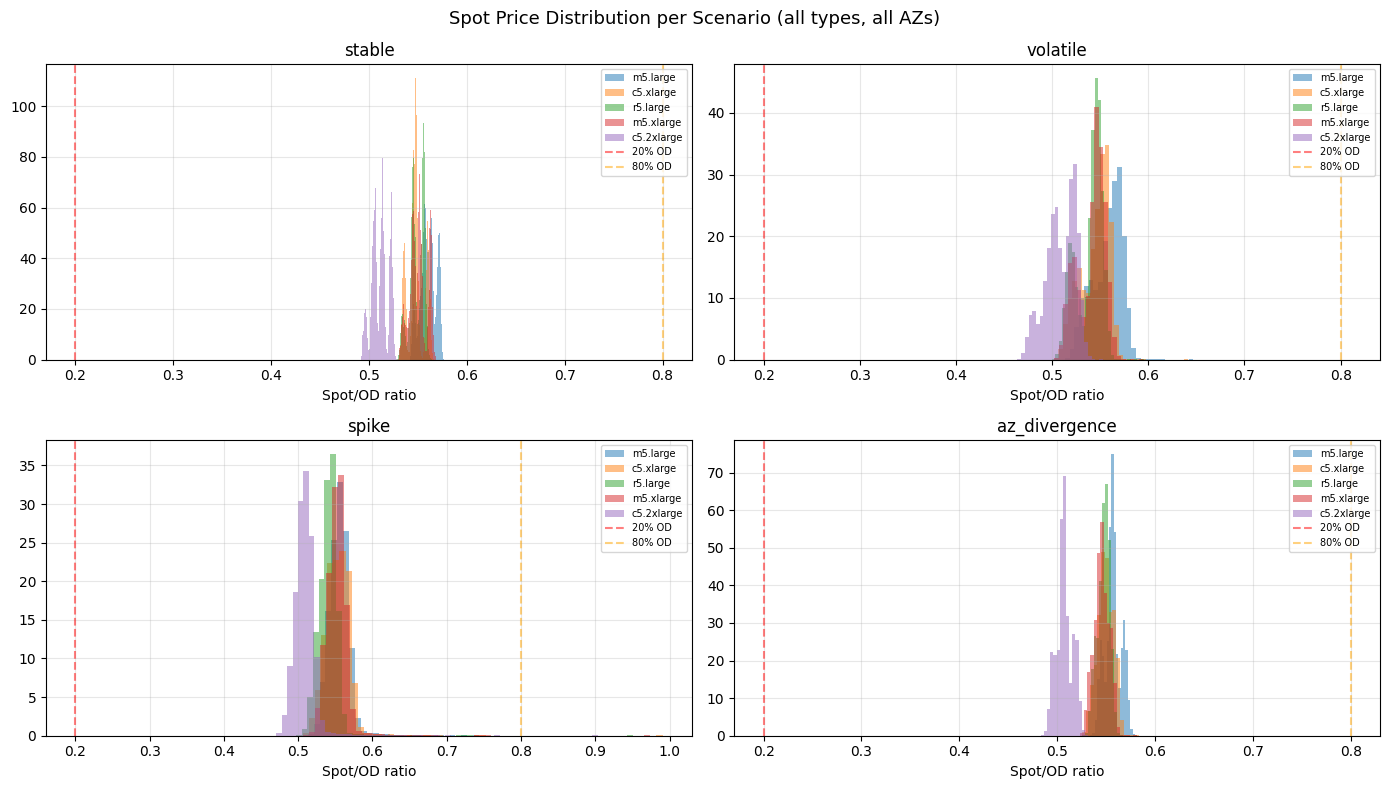

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Spot Price Distribution per Scenario (all types, all AZs)', fontsize=13)
colors = plt.cm.tab10.colors

for ax, scn in zip(axes.flat, SCENARIOS):
    df = dfs[scn]
    for i, itype in enumerate(INSTANCE_TYPES):
        sub = df[df['instance_type']==itype]['spot_price']
        od = OD_PRICES[itype]
        ax.hist(sub / od, bins=60, alpha=0.5, color=colors[i], label=itype, density=True)
    ax.axvline(0.2, color='red',   ls='--', alpha=0.5, label='20% OD')
    ax.axvline(0.8, color='orange',ls='--', alpha=0.5, label='80% OD')
    ax.set_title(scn)
    ax.set_xlabel('Spot/OD ratio')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/price_distribution.png', dpi=100)
plt.show()

## 6. Time series — 1 tuần đầu, m5.large, 3 AZs

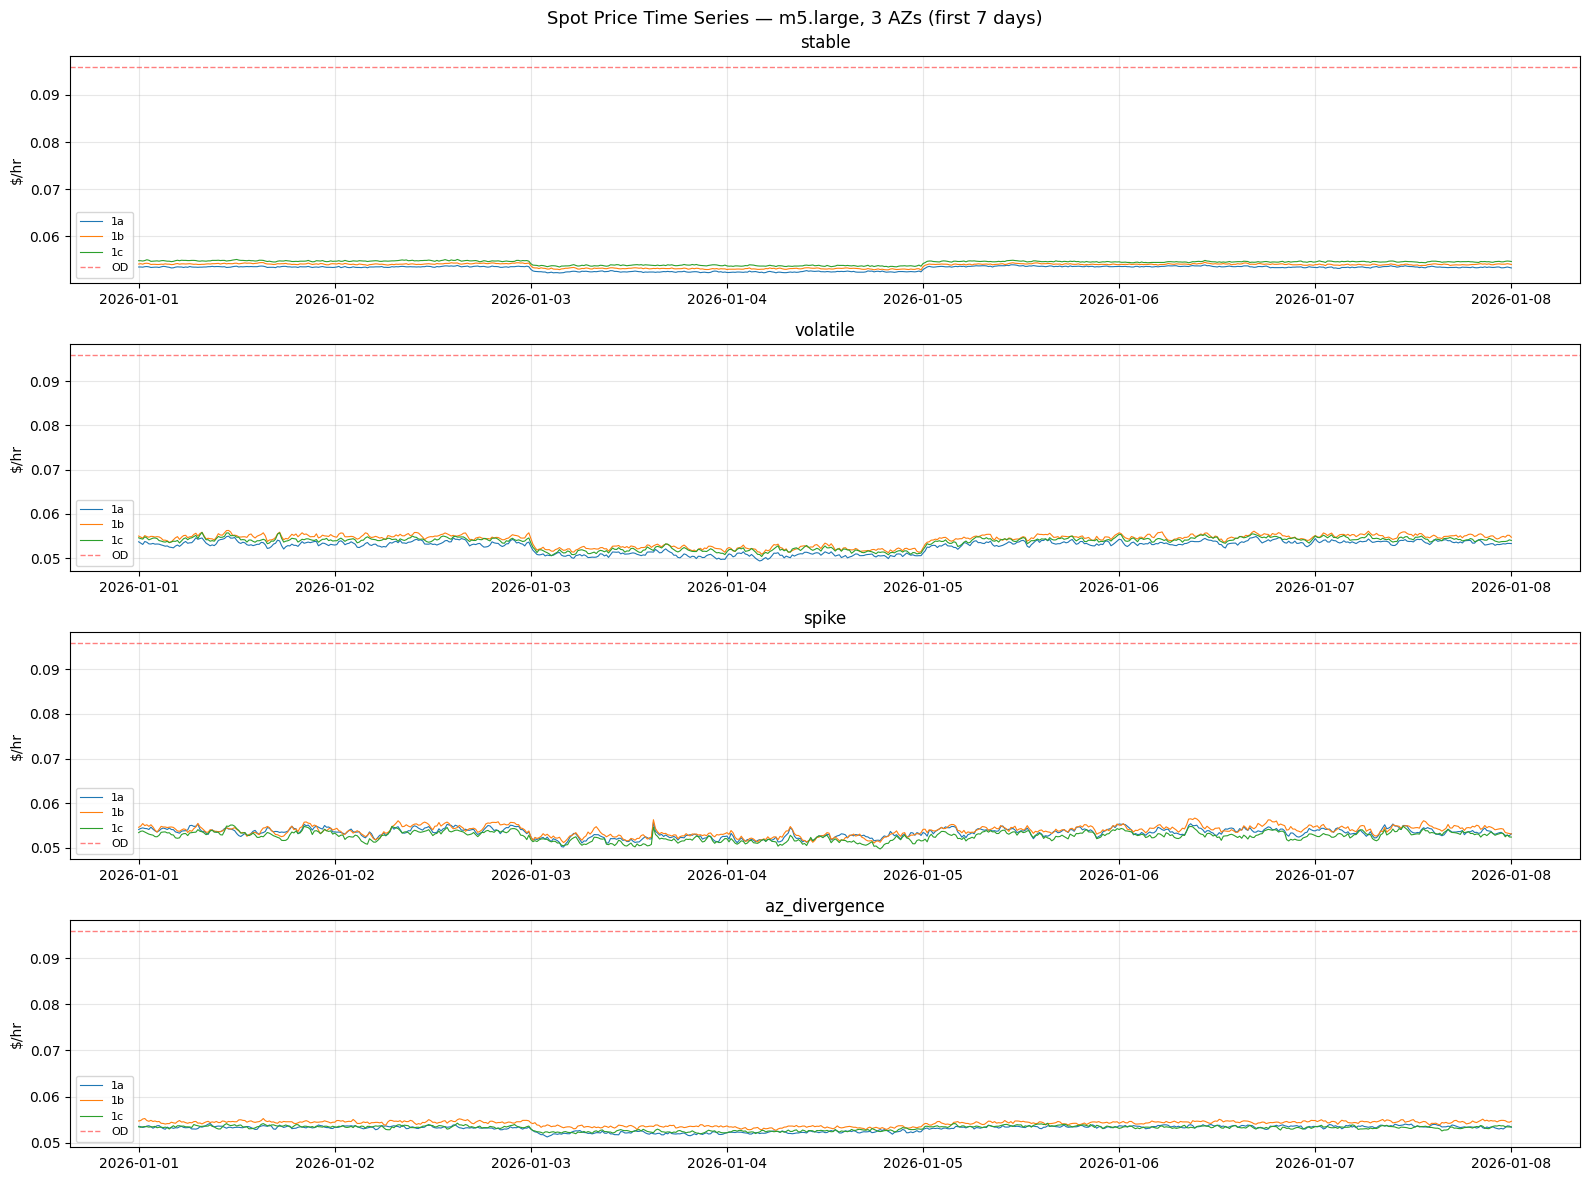

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=False)
fig.suptitle('Spot Price Time Series — m5.large, 3 AZs (first 7 days)', fontsize=13)
az_colors = {'ap-southeast-1a': '#1f77b4', 'ap-southeast-1b': '#ff7f0e', 'ap-southeast-1c': '#2ca02c'}

for ax, scn in zip(axes, SCENARIOS):
    df = dfs[scn]
    sub = df[df['instance_type']=='m5.large'].sort_values('timestamp')
    week1_end = sub['timestamp'].min() + pd.Timedelta(days=7)
    sub = sub[sub['timestamp'] <= week1_end]
    for az, col in az_colors.items():
        az_data = sub[sub['availability_zone']==az]
        ax.plot(az_data['timestamp'], az_data['spot_price'], color=col, lw=0.8, label=az[-2:])
    ax.axhline(OD_PRICES['m5.large'], color='red', ls='--', alpha=0.5, lw=1, label='OD')
    ax.set_ylabel('$/hr')
    ax.set_title(scn)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/timeseries_week1.png', dpi=100)
plt.show()

## 7. Capacity depth & interrupt probability

=== CAPACITY DEPTH & INTERRUPT PROB ===

stable:
  capacity_depth: mean=0.770  min=0.100  p5=0.511  p95=1.000
  near_zero (<0.1): 0.0%  (high interrupt risk)
  interrupt_prob: mean=0.110  max=0.345

volatile:
  capacity_depth: mean=0.746  min=0.000  p5=0.452  p95=0.999
  near_zero (<0.1): 0.1%  (high interrupt risk)
  interrupt_prob: mean=0.119  max=0.400

spike:
  capacity_depth: mean=0.718  min=0.000  p5=0.363  p95=0.994
  near_zero (<0.1): 0.6%  (high interrupt risk)
  interrupt_prob: mean=0.129  max=0.421

az_divergence:
  capacity_depth: mean=0.749  min=0.000  p5=0.456  p95=0.999
  near_zero (<0.1): 0.1%  (high interrupt risk)
  interrupt_prob: mean=0.118  max=0.400


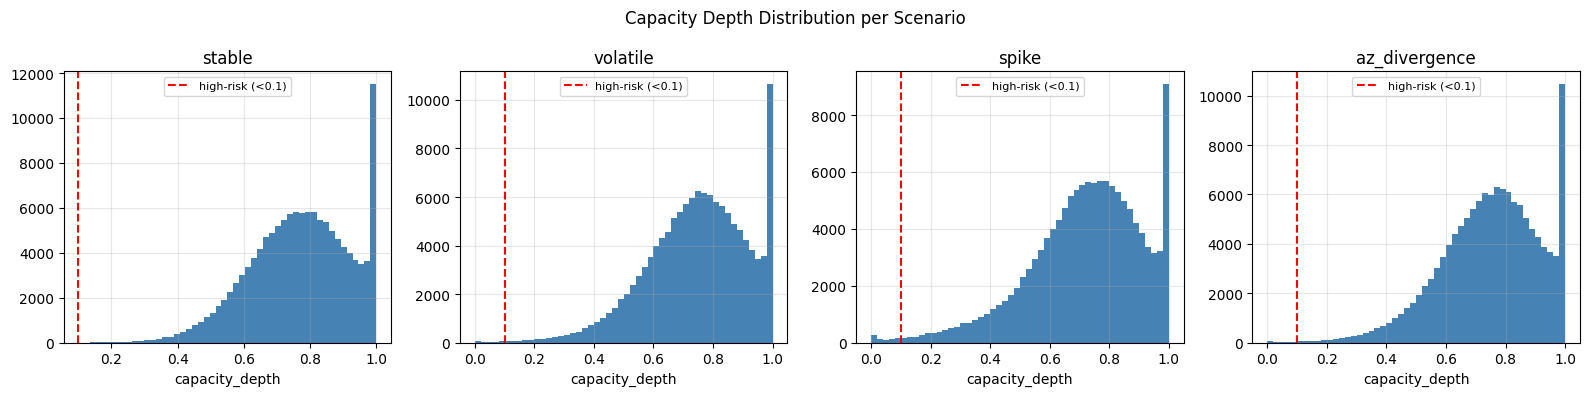

In [8]:
print('=== CAPACITY DEPTH & INTERRUPT PROB ===')
for scn in SCENARIOS:
    df = dfs[scn]
    cap = df['capacity_depth']
    iprob = df['est_interruption_prob'] if 'est_interruption_prob' in df.columns else None
    print(f'\n{scn}:')
    print(f'  capacity_depth: mean={cap.mean():.3f}  min={cap.min():.3f}  p5={cap.quantile(0.05):.3f}  p95={cap.quantile(0.95):.3f}')
    print(f'  near_zero (<0.1): {(cap < 0.1).mean():.1%}  (high interrupt risk)')
    if iprob is not None:
        print(f'  interrupt_prob: mean={iprob.mean():.3f}  max={iprob.max():.3f}')

# Plot capacity depth distribution
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Capacity Depth Distribution per Scenario', fontsize=12)
for ax, scn in zip(axes, SCENARIOS):
    dfs[scn]['capacity_depth'].hist(ax=ax, bins=50, color='steelblue', edgecolor='none')
    ax.axvline(0.1, color='red', ls='--', label='high-risk (<0.1)')
    ax.set_title(scn)
    ax.set_xlabel('capacity_depth')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Cross-type price spread — agent nên học chọn cheapest type

=== VCPU-NORMALIZED PRICE ($/vCPU/hr) — thứ tự cheapest ===

stable — mean spot price per vCPU:
  c5.2xlarge  : $0.1738/hr  $0.0217/vCPU  (OD: $0.340)
  c5.xlarge   : $0.0932/hr  $0.0233/vCPU  (OD: $0.170)
  m5.xlarge   : $0.1057/hr  $0.0264/vCPU  (OD: $0.192)
  m5.large    : $0.0538/hr  $0.0269/vCPU  (OD: $0.096)
  r5.large    : $0.0692/hr  $0.0346/vCPU  (OD: $0.126)


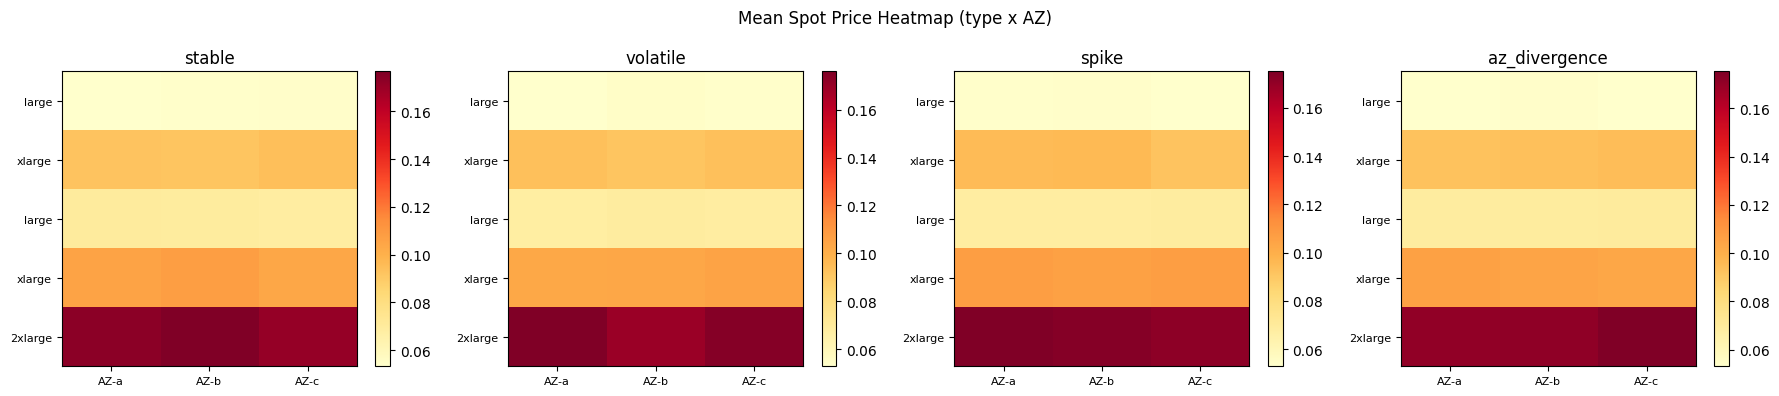

In [9]:
print('=== VCPU-NORMALIZED PRICE ($/vCPU/hr) — thứ tự cheapest ===')
VCPUS = {'m5.large': 2, 'c5.xlarge': 4, 'r5.large': 2, 'm5.xlarge': 4, 'c5.2xlarge': 8}

for scn in ['stable']:
    df = dfs[scn]
    print(f'\n{scn} — mean spot price per vCPU:')
    rows = []
    for itype in INSTANCE_TYPES:
        mean_p = df[df['instance_type']==itype]['spot_price'].mean()
        per_vcpu = mean_p / VCPUS[itype]
        rows.append((itype, mean_p, per_vcpu))
    for itype, p, pv in sorted(rows, key=lambda x: x[2]):
        print(f'  {itype:12s}: ${p:.4f}/hr  ${pv:.4f}/vCPU  (OD: ${OD_PRICES[itype]:.3f})')

# Heatmap: mean spot price per (type, AZ) for each scenario
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Mean Spot Price Heatmap (type x AZ)', fontsize=12)

for ax, scn in zip(axes, SCENARIOS):
    matrix = []
    for itype in INSTANCE_TYPES:
        row = []
        for az in AZS:
            val = dfs[scn][(dfs[scn]['instance_type']==itype) & (dfs[scn]['availability_zone']==az)]['spot_price'].mean()
            row.append(val)
        matrix.append(row)
    im = ax.imshow(matrix, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(3)); ax.set_xticklabels(['AZ-a','AZ-b','AZ-c'], fontsize=8)
    ax.set_yticks(range(5)); ax.set_yticklabels([t.split('.')[1] for t in INSTANCE_TYPES], fontsize=8)
    ax.set_title(scn)
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('../data/processed/price_heatmap.png', dpi=100)
plt.show()

## 9. Summary — Pass/Fail checklist

In [10]:
print('=' * 55)
print('DATA QUALITY CHECKLIST')
print('=' * 55)

all_pass = True
checks = []

for scn in SCENARIOS:
    df = dfs[scn].copy()
    df['od'] = df['instance_type'].map(OD_PRICES)
    df['ratio'] = df['spot_price'] / df['od']

    # Check 1: row count
    expected = len(INSTANCE_TYPES) * len(AZS)
    actual_pools = df.groupby(['instance_type','availability_zone']).ngroups
    c1 = actual_pools == expected

    # Check 2: spot/OD ratio 15-85%
    c2 = (df['ratio'].mean() >= 0.15) and (df['ratio'].mean() <= 0.85)

    # Check 3: no negative or zero prices
    c3 = (df['spot_price'] > 0).all()

    # Check 4: spike rate < 3%
    jumps = df.groupby(['instance_type','availability_zone'])['spot_price'].pct_change().abs()
    spike_rate = (jumps > 0.15).mean()
    c4 = spike_rate < 0.03

    # Check 5: capacity_depth in [0,1]
    c5 = (df['capacity_depth'] >= 0).all() and (df['capacity_depth'] <= 1).all()

    # Check 6: AZ correlation reasonable
    pivot = df[df['instance_type']=='m5.large'].pivot_table(
        index='timestamp', columns='availability_zone', values='spot_price')
    avg_corr = pivot.corr().values[np.triu_indices(3, k=1)].mean()
    c6 = (avg_corr > 0.1) and (avg_corr < 0.99)

    results = [c1, c2, c3, c4, c5, c6]
    labels  = ['15 pools', 'ratio 15-85%', 'no zero price', 'spike<3%', 'cap_depth [0,1]', 'AZ corr ok']
    passed  = all(results)
    all_pass = all_pass and passed

    status = 'PASS' if passed else 'FAIL'
    print(f'\n[{status}] {scn}')
    for label, ok in zip(labels, results):
        mark = 'OK' if ok else 'FAIL'
        extra = ''
        if label == 'ratio 15-85%': extra = f' (mean={df["ratio"].mean():.1%})'
        if label == 'spike<3%':     extra = f' ({spike_rate:.2%}/step)'
        if label == 'AZ corr ok':   extra = f' (avg={avg_corr:.2f})'
        print(f'  [{mark}] {label}{extra}')

print('\n' + '=' * 55)
print('OVERALL:', 'ALL PASS - Data ready for training!' if all_pass else 'SOME CHECKS FAILED - Review above')
print('=' * 55)

DATA QUALITY CHECKLIST

[PASS] stable
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.4%)
  [OK] no zero price
  [OK] spike<3% (0.00%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.92)

[PASS] volatile
  [OK] 15 pools
  [OK] ratio 15-85% (mean=53.9%)
  [OK] no zero price
  [OK] spike<3% (0.13%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.97)

[PASS] spike
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.3%)
  [OK] no zero price
  [OK] spike<3% (0.44%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.97)

[PASS] az_divergence
  [OK] 15 pools
  [OK] ratio 15-85% (mean=54.2%)
  [OK] no zero price
  [OK] spike<3% (0.04%/step)
  [OK] cap_depth [0,1]
  [OK] AZ corr ok (avg=0.79)

OVERALL: ALL PASS - Data ready for training!
